In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("heart.csv")
target = "HeartDisease"

print("First 5 rows: ")
print(df.head())
print("\nShape: ")
print(df.shape)
print("\nColumns:") 
print(df.columns.tolist())
print("\nData Types:")
print(df.dtypes)
print("\nDataset information:")
df.info()
print("\nStatistical summary:")
print(df.describe(include="all"))

First 5 rows: 
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

Shape: 
(918, 12)

Columns:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Data Type

In [30]:
print("\nMissing values:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# 5. Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()


Missing values:
Age                  0
RestingBP            0
Cholesterol          0
FastingBS            0
MaxHR                0
Oldpeak              0
HeartDisease         0
Sex_M                0
ChestPainType_ATA    0
ChestPainType_NAP    0
ChestPainType_TA     0
RestingECG_Normal    0
RestingECG_ST        0
ExerciseAngina_Y     0
ST_Slope_Flat        0
ST_Slope_Up          0
dtype: int64

Total missing values: 0

Duplicate rows: 0



Target counts:
HeartDisease
1    508
0    410
Name: count, dtype: int64


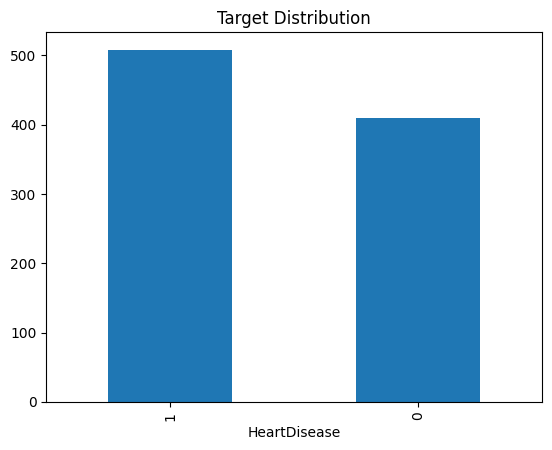

In [11]:
if target in df.columns:
    print("\nTarget counts:")
    print(df[target].value_counts(dropna=False))

    df[target].value_counts().plot(kind="bar")
    plt.title("Target Distribution")
    plt.show()

In [12]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("\nNumerical columns:", num_cols)
print("\nCategorical columns:", cat_cols)


Numerical columns: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease']

Categorical columns: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']


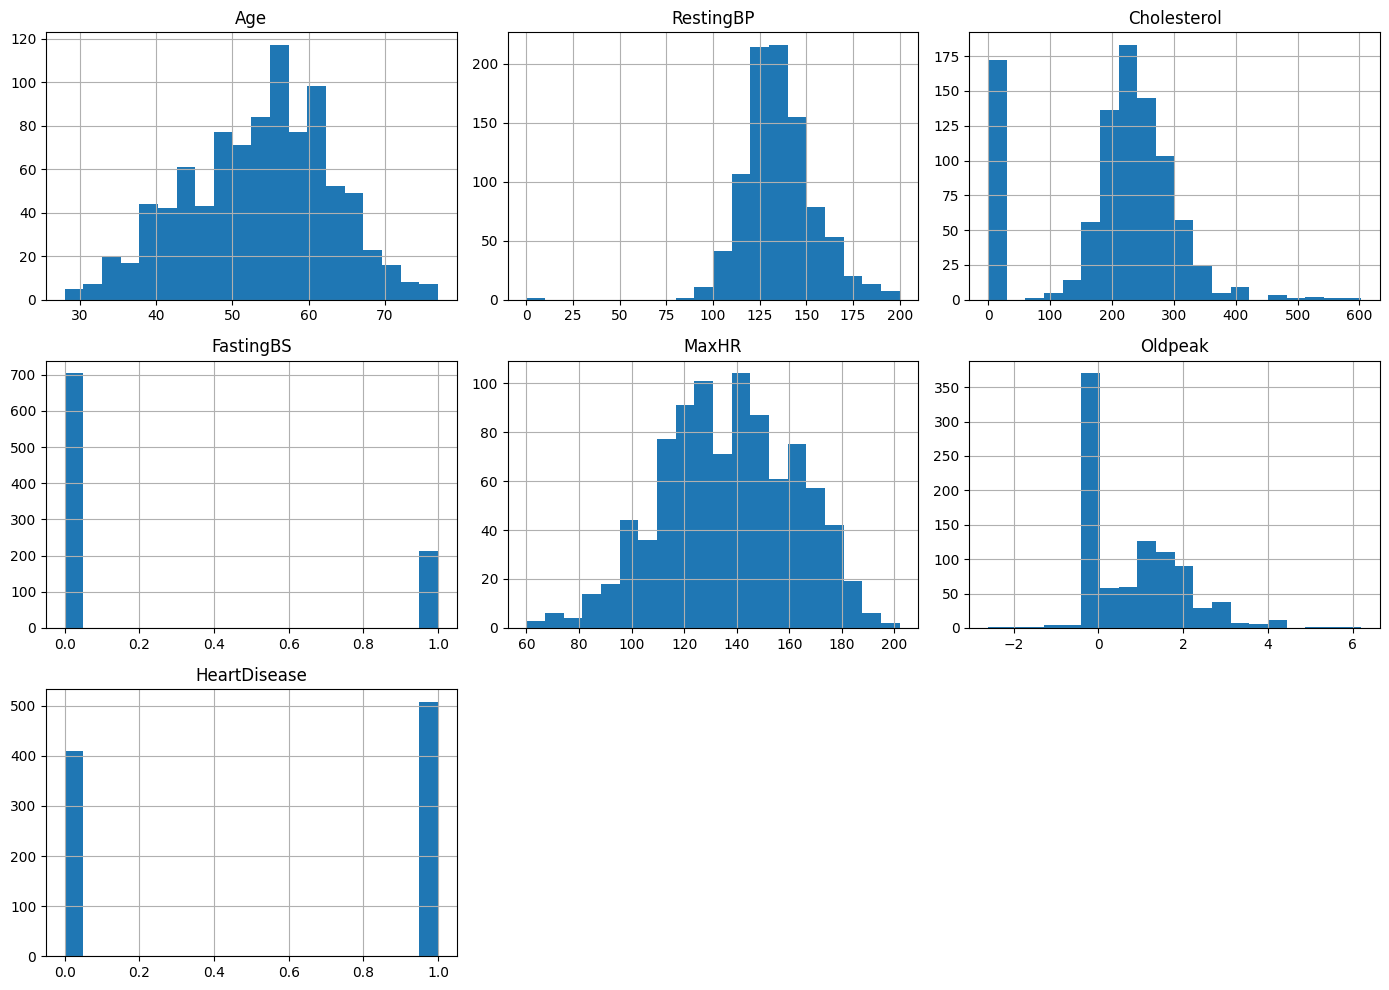

In [13]:
df[num_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

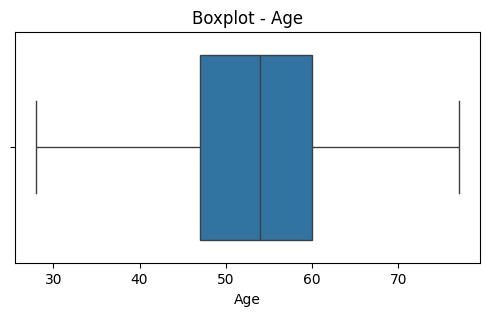

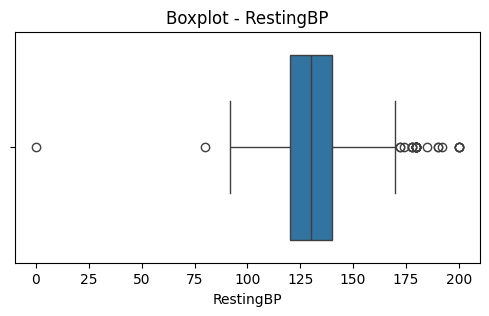

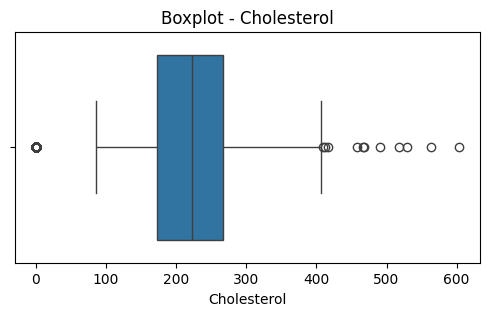

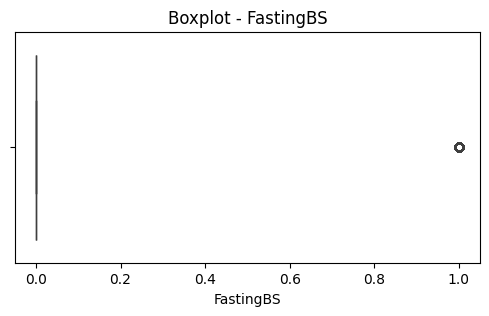

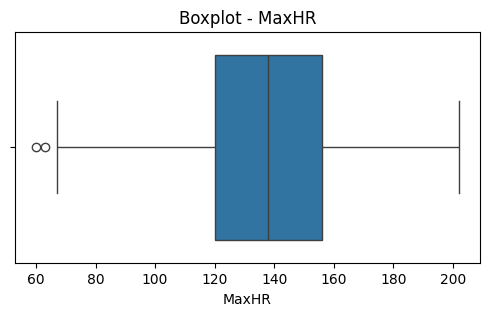

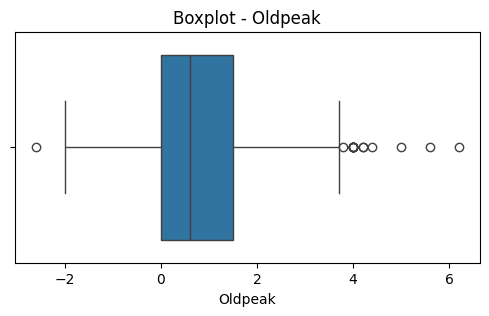

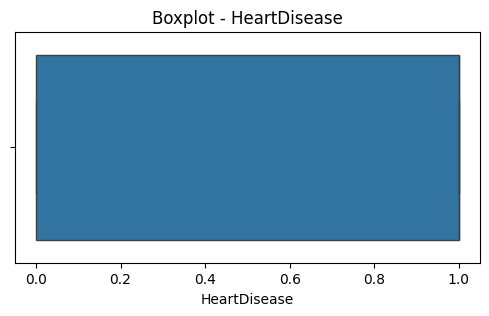

In [14]:
for col in num_cols:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[col])
    plt.title("Boxplot - " + col)
    plt.show()

In [15]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()
    print(col, "Outliers:", count)

Age Outliers: 0
RestingBP Outliers: 28
Cholesterol Outliers: 183
FastingBS Outliers: 214
MaxHR Outliers: 2
Oldpeak Outliers: 16
HeartDisease Outliers: 0


In [32]:
import seaborn as sns

# Opens the documentation in a pop-up window
sns.heatmap?

Signature:
sns.heatmap(
    data,
    *,
    vmin=None,
    vmax=None,
    cmap=None,
    center=None,
    robust=False,
    annot=None,
    fmt='.2g',
    annot_kws=None,
    linewidths=0,
    linecolor='white',
    cbar=True,
    cbar_kws=None,
    cbar_ax=None,
    square=False,
    xticklabels='auto',
    yticklabels='auto',
    mask=None,
    ax=None,
    **kwargs,
)
Docstring:
Plot rectangular data as a color-encoded matrix.

This is an Axes-level function and will draw the heatmap into the
currently-active Axes if none is provided to the ``ax`` argument.  Part of
this Axes space will be taken and used to plot a colormap, unless ``cbar``
is False or a separate Axes is provided to ``cbar_ax``.

Parameters
----------
data : rectangular dataset
    2D dataset that can be coerced into an ndarray. If a Pandas DataFrame
    is provided, the index/column information will be used to label the
    columns and rows.
vmin, vmax : floats, optional
    Values to anchor the colormap, otherwise

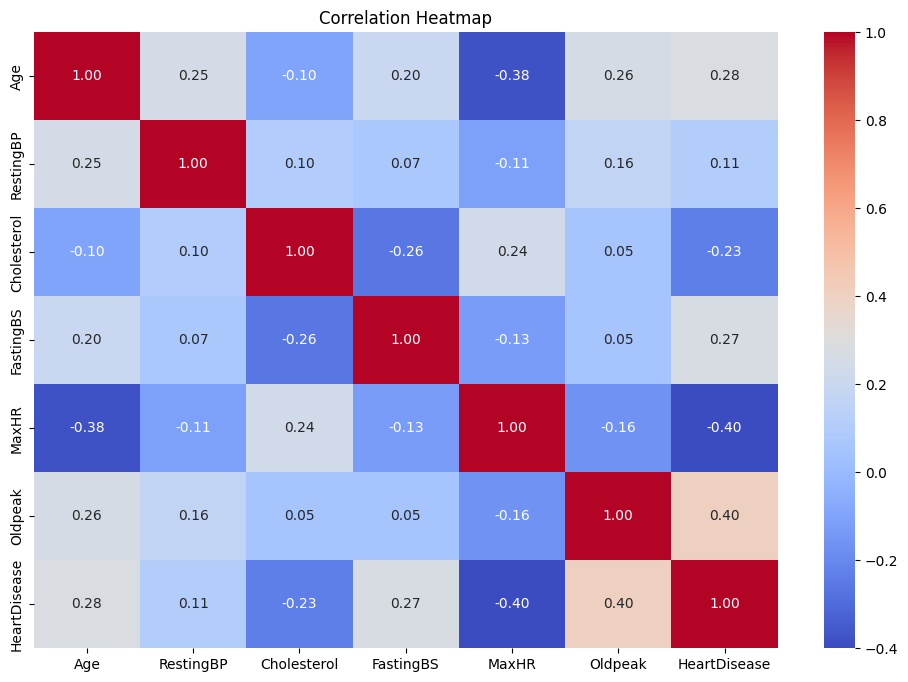

In [16]:
if len(num_cols) > 1:
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        df[num_cols].corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Correlation Heatmap")
    plt.show()


In [17]:
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in cat_cols:
    if df[col].isnull().any():
        mode = df[col].mode()
        if not mode.empty:
            df[col] = df[col].fillna(mode[0])

print("\nMissing values after filling:")
print(df.isnull().sum())

print("\nEDA completed!")



Missing values after filling:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

EDA completed!


In [34]:
# Find highly correlated features
corr = df[num_cols].corr()
features = corr.columns.drop(target)
c = corr.loc[features, features]

upper = c.where(
    np.triu(np.ones(c.shape), k=1).astype(bool)
)

drop_cols = [
    col for col in upper.columns
    if any(upper[col].abs() > 0.85)
]

# Remove redundant features, keeping the target
df_selected = df.drop(columns=drop_cols)

print("Removed features:", drop_cols)
print("Selected features:", df_selected.columns.tolist())

Removed features: []
Selected features: ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak', 'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up']


In [35]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("heart.csv")
target = "HeartDisease"

# Handle missing values
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].median())

# Encode categorical columns instead of get_dummies
encoders = {}

for col in df.select_dtypes(include="object").columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    encoders[col] = le

print("Encoded dataset:")
print(df.head())

# Separate features and target
X = df.drop(columns=[target])
y = df[target]

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Encoded dataset:
   Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
0   40    1              1        140          289          0           1   
1   49    0              2        160          180          0           1   
2   37    1              1        130          283          0           2   
3   48    0              0        138          214          0           1   
4   54    1              2        150          195          0           1   

   MaxHR  ExerciseAngina  Oldpeak  ST_Slope  HeartDisease  
0    172               0      0.0         2             0  
1    156               0      1.0         1             1  
2     98               0      0.0         2             0  
3    108               1      1.5         1             1  
4    122               0      0.0         2             0  
Training shape: (734, 11)
Testing shape: (184, 11)


In [37]:
from sklearn.model_selection import GridSearchCV

# KNN pipeline
knn_pipe = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier()
)

knn_params = {
    "kneighborsclassifier__n_neighbors": [3, 5, 7, 9, 11],
    "kneighborsclassifier__weights": ["uniform", "distance"],
    "kneighborsclassifier__metric": ["euclidean", "manhattan"]
}

knn_grid = GridSearchCV(
    knn_pipe,
    knn_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

best_knn = knn_grid.best_estimator_

print("Best KNN Parameters:", knn_grid.best_params_)
print("Best KNN CV Accuracy:", knn_grid.best_score_)
print("KNN Test Accuracy:",
      accuracy_score(y_test, best_knn.predict(X_test)))


# SVM pipeline
svm_pipe = make_pipeline(
    StandardScaler(),
    SVC()
)

svm_params = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", "auto"]
}

svm_grid = GridSearchCV(
    svm_pipe,
    svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

svm_grid.fit(X_train, y_train)

best_svm = svm_grid.best_estimator_

print("\nBest SVM Parameters:", svm_grid.best_params_)
print("Best SVM CV Accuracy:", svm_grid.best_score_)
print("SVM Test Accuracy:",
      accuracy_score(y_test, best_svm.predict(X_test)))

Best KNN Parameters: {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 9, 'kneighborsclassifier__weights': 'uniform'}
Best KNN CV Accuracy: 0.8582983878482899
KNN Test Accuracy: 0.9130434782608695

Best SVM Parameters: {'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
Best SVM CV Accuracy: 0.8609635635075948
SVM Test Accuracy: 0.8858695652173914


In [38]:
for k in [3, 5, 7]:
    knn = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )

    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)

    print("KNN k =", k,
          "Accuracy =", accuracy_score(y_test, y_pred))

KNN k = 3 Accuracy = 0.875
KNN k = 5 Accuracy = 0.8913043478260869
KNN k = 7 Accuracy = 0.8913043478260869


In [39]:
for kernel in ["linear", "rbf", "poly"]:
    svm = make_pipeline(
        StandardScaler(),
        SVC(kernel=kernel)
    )

    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)

    print("SVM kernel =", kernel,
          "Accuracy =", accuracy_score(y_test, y_pred))

SVM kernel = linear Accuracy = 0.8695652173913043
SVM kernel = rbf Accuracy = 0.8858695652173914
SVM kernel = poly Accuracy = 0.8913043478260869


In [41]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

models = [
    ("Tuned KNN", best_knn),
    ("Tuned SVM", best_svm)
]

for name, model in models:
    y_pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

    train = model.score(X_train, y_train)
    test = model.score(X_test, y_test)

    print("Training Accuracy:", train)
    print("Testing Accuracy:", test)

    if train - test > 0.10:
        print("Overfitting")
    elif train < 0.70 and test < 0.70:
        print("Underfitting")
    else:
        print("Generalizing Well")



 Tuned KNN
Accuracy: 0.9130434782608695
Precision: 0.9134615384615384
Recall: 0.9313725490196079
F1-score: 0.9223300970873787
Confusion Matrix:
 [[73  9]
 [ 7 95]]
Training Accuracy: 0.8773841961852861
Testing Accuracy: 0.9130434782608695
Generalizing Well

 Tuned SVM
Accuracy: 0.8858695652173914
Precision: 0.8648648648648649
Recall: 0.9411764705882353
F1-score: 0.9014084507042254
Confusion Matrix:
 [[67 15]
 [ 6 96]]
Training Accuracy: 0.9073569482288828
Testing Accuracy: 0.8858695652173914
Generalizing Well


In [40]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, model in [
    ("Tuned KNN", best_knn),
    ("Tuned SVM", best_svm)
]:
    scores = cross_validate(
        model,
        X, y,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    print("\n", name)
    print("Accuracy:", scores["test_accuracy"].mean())
    print("Precision:", scores["test_precision"].mean())
    print("Recall:", scores["test_recall"].mean())
    print("F1-score:", scores["test_f1"].mean())


 Tuned KNN
Accuracy: 0.8693216916132098
Precision: 0.8768763641821515
Recall: 0.8899437002523782
F1-score: 0.8826545263882283

 Tuned SVM
Accuracy: 0.8627821335234023
Precision: 0.8570086122656215
Recall: 0.9036497767423801
F1-score: 0.8792697641062546


In [26]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Standalone SVM
svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear")
)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

# AdaBoost with SVM base learner
ada = AdaBoostClassifier(
    estimator=SVC(kernel="linear", probability=True),
    n_estimators=10,
    random_state=42
)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

print("AdaBoost-SVM Accuracy:", accuracy_score(y_test, ada_pred))

SVM Accuracy: 0.875
AdaBoost-SVM Accuracy: 0.8260869565217391


In [27]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Models
models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf")
}

# Before PCA
for name, model in models.items():
    pipe = make_pipeline(StandardScaler(), model)
    pipe.fit(X_train, y_train)
    print(name, "Before PCA:", pipe.score(X_test, y_test))

# Standardize data for PCA
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Calculate explained variance
pca = PCA()
pca.fit(X_train_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Cumulative variance:", pca.explained_variance_ratio_.cumsum())

# Retain 90% variance
pca = PCA(n_components=0.90)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Components required:", pca.n_components_)

# After PCA
for name, model in models.items():
    model.fit(X_train_pca, y_train)
    print(name, "After PCA:", model.score(X_test_pca, y_test))

KNN Before PCA: 0.8858695652173914
SVM Before PCA: 0.9021739130434783
Explained variance ratio: [0.22877494 0.11177684 0.09560017 0.08055152 0.07456533 0.07249647
 0.06112412 0.05481196 0.05146965 0.04303873 0.03840573 0.03029055
 0.02924592 0.02147342 0.00637463]
Cumulative variance: [0.22877494 0.34055178 0.43615195 0.51670347 0.5912688  0.66376527
 0.72488939 0.77970135 0.83117101 0.87420974 0.91261547 0.94290602
 0.97215195 0.99362537 1.        ]
Components required: 11
KNN After PCA: 0.8913043478260869
SVM After PCA: 0.9021739130434783


In [28]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from scipy.stats import ttest_rel, f_oneway, wilcoxon, friedmanchisquare
from scipy.stats import f as f_dist
import numpy as np

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = [
    make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
]

names = ["KNN", "SVM", "Logistic Regression"]
scores = []

for name, model in zip(names, models):
    s = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    scores.append(s)
    print(name, "Fold accuracies:", s)
    print(name, "Mean accuracy:", s.mean())

knn, svm, lr = scores

# 1. Paired t-test: KNN vs SVM
print("Paired t-test:", ttest_rel(knn, svm))

# 2. Wilcoxon signed-rank test: KNN vs SVM
print("Wilcoxon test:", wilcoxon(knn, svm))

# 3. One-way ANOVA: compare three models
print("ANOVA:", f_oneway(knn, svm, lr))

# 4. Friedman test: compare three models
print("Friedman test:", friedmanchisquare(knn, svm, lr))

# 5. F-test: compare variances of KNN and SVM scores
v1, v2 = np.var(knn, ddof=1), np.var(svm, ddof=1)
F = v1 / v2 if v2 != 0 else np.inf
df1, df2 = len(knn) - 1, len(svm) - 1
p = 2 * min(f_dist.cdf(F, df1, df2), f_dist.sf(F, df1, df2))
print("F-statistic:", F)
print("F-test p-value:", min(p, 1.0))

KNN Fold accuracies: [0.86956522 0.83695652 0.83695652 0.8852459  0.82513661]
KNN Mean accuracy: 0.8507721549061535
SVM Fold accuracies: [0.91304348 0.84782609 0.83152174 0.87431694 0.8579235 ]
SVM Mean accuracy: 0.8649263483012593
Logistic Regression Fold accuracies: [0.88586957 0.875      0.8423913  0.89071038 0.84153005]
Logistic Regression Mean accuracy: 0.8671002613447374
Paired t-test: TtestResult(statistic=np.float64(-1.340212734807702), pvalue=np.float64(0.25123875293242603), df=np.int64(4))
Wilcoxon test: WilcoxonResult(statistic=np.float64(4.0), pvalue=np.float64(0.4375))
ANOVA: F_onewayResult(statistic=np.float64(0.5435405608470733), pvalue=np.float64(0.5943341834136168))
Friedman test: FriedmanchisquareResult(statistic=np.float64(3.6000000000000014), pvalue=np.float64(0.1652988882215864))
F-statistic: 0.6684014137494235
F-test p-value: 0.705797181736789
